In [49]:
from pathlib import Path
import pandas as pd
from credit_card_fraud_detection.paths import ROOT, INTERIM, MODELS, PROCESSED
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
train = INTERIM / "train_interim.csv"
test = INTERIM / "test_interim.csv"

In [35]:
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

In [36]:
Xtr_features = train_df.columns.to_list()
ytr_features = Xtr_features.pop()

X = train_df[Xtr_features]
y = train_df[ytr_features]

In [37]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=0)

In [38]:
Xtr.head()

,Unnamed: 0,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
110257,110257,110257,45.29,20.68,5,1.95,53,53,1214.19,0,...,Visa,3D Secure,ATM,Android Phone,False,False,False,False,False,False
240700,240700,240700,20.07,4.44,6,21.36,37,63,9094.29,0,...,Visa,OTP,POS,Android Phone,False,False,False,False,False,False
531253,531253,531253,22.63,3.11,1,18.18,53,67,5046.61,0,...,Mastercard,No Authentication,Online,POS Terminal,False,False,False,False,False,False
691441,691441,691441,47.73,14.94,2,0.31,47,56,1488.58,0,...,RuPay,PIN,POS,Android Phone,True,False,False,False,False,False
60833,60833,60833,31.56,3.24,3,6.56,45,24,1156.43,0,...,Mastercard,PIN,Contactless,Android Phone,False,False,False,False,False,False


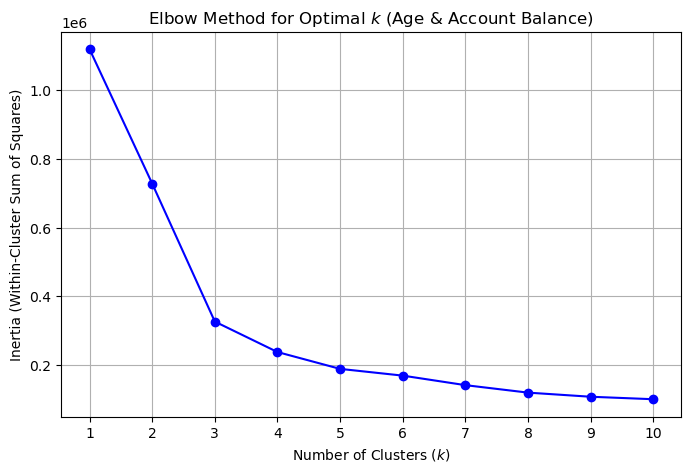

In [39]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
import xgboost as xgb
import pandas as pd
import numpy as np
import joblib
# pair 1
cols_pair1 = ["customer_age", "account_balance_usd"]


# Scale features 
scalar1 = StandardScaler()
Xtr_scaled_1 = scalar1.fit_transform(Xtr[cols_pair1])


inertia = []
k_range = range(1,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
    kmeans.fit(Xtr_scaled_1)
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker="o", linestyle="-", color="b")
plt.title("Elbow Method for Optimal $k$ (Age & Account Balance)")
plt.xlabel("Number of Clusters ($k$)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(k_range)
plt.grid(True)
plt.show()


In [40]:
class CustomerClustering(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=4):
        self.n_clusters = n_clusters
        self.scalers = {}
        self.kmeans_models = {}

    def fit(self, X, y=None):
        self.pairs_ = {
            "age_balance": ["customer_age", "account_balance_usd"],
            "age_spend": ["customer_age", "amount_usd"]
        }

        for name, cols in self.pairs_.items():
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X[cols])
            self.scalers[name] = scaler
            
            kmeans = KMeans(n_clusters=self.n_clusters, random_state=42, n_init="auto")
            kmeans.fit(X_scaled)
            self.kmeans_models[name] = kmeans
            
        return self

    def transform(self, X):
        X = X.copy()

        X["spending_ratio"] = X["amount_usd"]/(X["account_balance_usd"] + 1e-5) #to avoid division by zero error
        X["spend_per_age"] = X["amount_usd"]/(X["customer_age"] + 1e-5)

        # find median
        median_balance = X["account_balance_usd"].median()
        median_spend = X["amount_usd"].median()
        X["high_spend_low_balance"] = ((X["account_balance_usd"] < median_balance) & (X["amount_usd"] > median_spend)).astype(int)

        for name, cols in self.pairs_.items():
            X_scaled = self.scalers[name].transform(X[cols])
            cluster_col_name = f"{name}_cluster"
            X[cluster_col_name] = self.kmeans_models[name].predict(X_scaled)

            X[cluster_col_name] = X[cluster_col_name].astype("category")

        categorical_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']
        for col in categorical_cols:
            if col in X.columns:
                X[col] = X[col].astype("category")
        return X


In [ ]:
# to solve class imbalance issues
neg_count = (ytr == 0).sum()
pos_count = (ytr == 1).sum()
weight_ratio = neg_count / pos_count

model_pipeline = make_pipeline(
    CustomerClustering(n_clusters=3),
    xgb.XGBClassifier(
        enable_categorical=True,
        tree_method="hist",
        scale_pos_weight = weight_ratio,
        random_state = 0,
        n_estimatorss = 100
    )
)

model_pipeline.fit(Xtr, ytr)

model_location = MODELS / "credit_card_fraud_model.pkl"

joblib.dump(model_pipeline, model_location)

predictions = model_pipeline.predict(Xte)
probabilities = model_pipeline.predict_proba(Xte)

[10:33:46] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "n_estimatorss" } are not used.



In [42]:
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    classification_report, 
    confusion_matrix
)

In [43]:
y_pred = model_pipeline.predict(Xte)

y_pred_proba = model_pipeline.predict_proba(Xte)

print(f"Accuracy:  {accuracy_score(yte, y_pred):.4f}")
print(f"Precision: {precision_score(yte, y_pred):.4f}")
print(f"Recall:    {recall_score(yte, y_pred):.4f}")
print(f"F1-Score:  {f1_score(yte, y_pred):.4f}")

try:
    print(f"ROC-AUC:   {roc_auc_score(yte, y_pred_proba):.4f}")
except ValueError:
    pass

print("\n--- Classification Report ---")
print(classification_report(yte, y_pred))

# Confusion Matrix
print("\n--- Confusion Matrix ---")
print(confusion_matrix(yte, y_pred))



Accuracy:  0.9145
Precision: 0.1350
Recall:    0.7618
F1-Score:  0.2293

--- Classification Report ---
              precision    recall  f1-score   support

         0.0       1.00      0.92      0.95    137654
         1.0       0.13      0.76      0.23      2338

    accuracy                           0.91    139992
   macro avg       0.57      0.84      0.59    139992
weighted avg       0.98      0.91      0.94    139992


--- Confusion Matrix ---
[[126240  11414]
 [   557   1781]]


<Figure size 600x600 with 0 Axes>

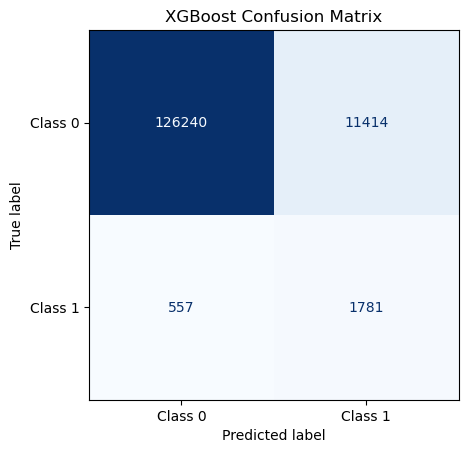

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    yte, 
    y_pred, 
    display_labels=["Class 0", "Class 1"],  # Note: it's display_labels, not display_columns
    cmap="Blues",
    colorbar=False
)
plt.title("XGBoost Confusion Matrix")
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_probs = model_pipeline.predict_proba(Xte)[:, 1]

custom_threshold = 0.70 

y_pred_custom = (y_probs >= custom_threshold).astype(int)

print(f"--- Metrics using threshold of {custom_threshold} ---")
print(classification_report(yte, y_pred_custom))

print("\n--- New Confusion Matrix ---")
print(confusion_matrix(yte, y_pred_custom))

--- Metrics using threshold of 0.7 ---
              precision    recall  f1-score   support

         0.0       0.99      0.96      0.98    137654
         1.0       0.21      0.66      0.32      2338

    accuracy                           0.95    139992
   macro avg       0.60      0.81      0.65    139992
weighted avg       0.98      0.95      0.96    139992


--- New Confusion Matrix ---
[[131891   5763]
 [   784   1554]]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

y_scores = model_pipeline.predict_proba(Xte)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(yte, y_scores)

metrics_df = pd.DataFrame({
    'Threshold': np.append(thresholds, 1.0),
    'Precision': precisions,
    'Recall': recalls
})

print(metrics_df[metrics_df['Precision'] >= 0.40].head(15))

        Threshold  Precision    Recall
136783   0.890295   0.400070  0.491446
136784   0.890356   0.400209  0.491446
136785   0.890363   0.400348  0.491446
136786   0.890480   0.400488  0.491446
136787   0.890593   0.400628  0.491446
136788   0.890598   0.400767  0.491446
136789   0.890613   0.400907  0.491446
136790   0.890632   0.401047  0.491446
136791   0.890668   0.401187  0.491446
136792   0.890696   0.401327  0.491446
136793   0.890813   0.401468  0.491446
136794   0.890816   0.401608  0.491446
136795   0.890827   0.401748  0.491446
136796   0.890841   0.401539  0.491018
136797   0.890845   0.401330  0.490590


In [47]:
chosen_threshold = 0.890295

y_probs = model_pipeline.predict_proba(Xte)[:, 1]
y_pred_final = (y_probs >= chosen_threshold).astype(int)

print(classification_report(yte, y_pred_final))
print(confusion_matrix(yte, y_pred_final))

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99    137654
         1.0       0.40      0.49      0.44      2338

    accuracy                           0.98    139992
   macro avg       0.70      0.74      0.72    139992
weighted avg       0.98      0.98      0.98    139992

[[135932   1722]
 [  1189   1149]]


In [48]:
import joblib

# Bundle the pipeline and the optimal threshold together
production_bundle = {
    "pipeline": model_pipeline,
    "decision_threshold": 0.890295
}


model_location = MODELS / "fraud_detection_system.pkl"

joblib.dump(production_bundle, model_location)

['C:\\Users\\shank\\OneDrive\\Documents\\Data analysis\\credit_card_fraud_detection\\models\\fraud_detection_system.pkl']

In [51]:
# testing on new data
bundle = joblib.load(model_location)

model_pipeline = bundle["pipeline"]
treshold = bundle["decision_threshold"]

y_new_probs = model_pipeline.predict_proba(test_df)[:, 1]

new_predictions = (y_new_probs >= treshold).astype(float)

outpout_df = pd.DataFrame({
    "id": test_df["id"],
    "is_fraud": new_predictions
}) 

display(outpout_df.head())

output_loc = PROCESSED / "submission.csv"

outpout_df.to_csv(output_loc, index=False)

,id,is_fraud
0,699960,0.0
1,699961,0.0
2,699962,0.0
3,699963,0.0
4,699964,0.0


In [52]:
outpout_df["is_fraud"].value_counts()

is_fraud
0.0    293996
1.0      5988
Name: count, dtype: int64